In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
claims = pd.read_csv("claims.csv")
policies = pd.read_csv("policies.csv")
customers = pd.read_csv("customers.csv")
incidents = pd.read_csv("incidents.csv")
processing = pd.read_csv("processing.csv")

datasets = {
    "claims": claims,
    "policies": policies,
    "customers": customers,
    "incidents": incidents,
    "processing": processing
}

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [ ]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    display(df.head())


CLAIMS


,claim_number,customer_id,policy_id,claim_date,claim_type,claim_amount,status
0,CLM00001,CUS00163,POL00074,2025-01-13,motor,50087.51,Settled
1,CLM00002,CUS00391,POL00288,2025-09-22,motor,48732.18,Settled
2,CLM00003,CUS00356,POL00319,2025-07-20,Property,63531.21,Rejected
3,CLM00004,CUS00509,POL00248,2024-03-03,Property,162547.30,Settled
4,CLM00005,CUS00325,POL00782,2025-11-17,motor,83951.50,Settled



POLICIES


,policy_id,policy_type,annual_premium,policy_tenure_years
0,POL00074,Home,37531.17,5
1,POL00288,Property,14567.59,7
2,POL00319,Commercial Property,41027.87,9
3,POL00248,Property,21439.91,3
4,POL00782,Motor,15813.60,8



CUSTOMERS


,customer_id,region,customer_tenure_years
0,CUS00163,West,3
1,CUS00391,Central,8
2,CUS00356,Central,2
3,CUS00509,South,10
4,CUS00325,South,4



INCIDENTS


,claim_number,incident_type,location_type,severity
0,CLM00001,Accidental Damage,Urban,Critical
1,CLM00002,Flood,Rural,High
2,CLM00003,Storm,Rural,Medium
3,CLM00004,Theft,Industrial Area,Medium
4,CLM00005,Theft,Rural,High



PROCESSING


,claim_number,assignee,process_stage,settlement_days
0,CLM00001,R. Arun,Investigation,27
1,CLM00002,A. Kumar,Assessment,19
2,CLM00003,R. Arun,Investigation,17
3,CLM00004,M. Divya,Payment,12
4,CLM00005,K. Sanjay,Registration,7


In [ ]:
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

claims: 1200 rows, 7 columns
policies: 1200 rows, 4 columns
customers: 1200 rows, 3 columns
incidents: 1200 rows, 4 columns
processing: 1200 rows, 4 columns


In [ ]:
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    df.info()


--- CLAIMS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   claim_number  1200 non-null   object 
 1   customer_id   1200 non-null   object 
 2   policy_id     1200 non-null   object 
 3   claim_date    1200 non-null   object 
 4   claim_type    1200 non-null   object 
 5   claim_amount  1200 non-null   float64
 6   status        1200 non-null   object 
dtypes: float64(1), object(6)
memory usage: 65.8+ KB

--- POLICIES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   policy_id            1200 non-null   object 
 1   policy_type          1200 non-null   object 
 2   annual_premium       1200 non-null   float64
 3   policy_tenure_years  1200 non-null   int64  
dtypes: float6

In [ ]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    missing = df.isnull().sum()
    result = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage": (missing / len(df) * 100).round(2)
    })
    display(result)


CLAIMS


,Missing Count,Missing Percentage
claim_number,0,0.0
customer_id,0,0.0
policy_id,0,0.0
claim_date,0,0.0
claim_type,0,0.0
claim_amount,0,0.0
status,0,0.0



POLICIES


,Missing Count,Missing Percentage
policy_id,0,0.0
policy_type,0,0.0
annual_premium,0,0.0
policy_tenure_years,0,0.0



CUSTOMERS


,Missing Count,Missing Percentage
customer_id,0,0.0
region,0,0.0
customer_tenure_years,0,0.0



INCIDENTS


,Missing Count,Missing Percentage
claim_number,0,0.00
incident_type,18,1.50
location_type,15,1.25
severity,12,1.00



PROCESSING


,Missing Count,Missing Percentage
claim_number,0,0.0
assignee,0,0.0
process_stage,0,0.0
settlement_days,0,0.0


In [ ]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} completely duplicated rows")

claims: 0 completely duplicated rows
policies: 0 completely duplicated rows
customers: 5 completely duplicated rows
incidents: 0 completely duplicated rows
processing: 0 completely duplicated rows


In [ ]:
duplicate_claims = claims[
    claims["claim_number"].duplicated(keep=False)
].sort_values("claim_number")

print("Rows associated with duplicate claim numbers:",
      len(duplicate_claims))

display(duplicate_claims)

Rows associated with duplicate claim numbers: 27


,claim_number,customer_id,policy_id,claim_date,claim_type,claim_amount,status
6,CLM00007,CUS00159,POL00349,2025-06-30,Comprehensive Motor,77000.65,Pending
831,CLM00007,CUS00013,POL00263,2025-07-28,Property,60993.62,Settled
529,CLM00007,CUS00578,POL00572,2024-07-26,Motor,88847.44,Settled
11,CLM00012,CUS00249,POL00797,2024-06-05,MOTOR,74380.74,Rejected
928,CLM00012,CUS00170,POL00776,2025-01-16,MOTOR,79141.18,Settled
12,CLM00013,CUS00775,POL00287,2024-03-13,motor,46838.80,Settled
920,CLM00013,CUS00268,POL00601,2025-12-22,Comprehensive Motor,8561.07,Settled
1101,CLM00016,CUS00605,POL00882,2026-09-05,Comprehensive Motor,36893.28,Pending
15,CLM00016,CUS00010,POL00042,2024-11-13,Motor,42127.70,Settled
304,CLM00019,CUS00182,POL00739,2024-11-07,Motor,18347.54,Settled


In [ ]:
print("Duplicate policy IDs:",
      policies["policy_id"].duplicated().sum())

print("Duplicate customer IDs:",
      customers["customer_id"].duplicated().sum())

print("Duplicate incident claim numbers:",
      incidents["claim_number"].duplicated().sum())

print("Duplicate processing claim numbers:",
      processing["claim_number"].duplicated().sum())

Duplicate policy IDs: 536
Duplicate customer IDs: 564
Duplicate incident claim numbers: 14
Duplicate processing claim numbers: 14


In [ ]:
print("CLAIM AMOUNTS")
display(claims["claim_amount"].describe())

print("\nPREMIUMS")
display(policies["annual_premium"].describe())

print("\nSETTLEMENT DAYS")
display(processing["settlement_days"].describe())

CLAIM AMOUNTS


,claim_amount
count,1.200000e+03
mean,8.341287e+04
std,9.635696e+05
min,-4.050000e+03
25%,1.621924e+04
50%,2.919238e+04
75%,5.313976e+04
max,3.240000e+07



PREMIUMS


,annual_premium
count,1200.000000
mean,23014.099633
std,11209.544123
min,3589.620000
25%,13782.557500
50%,23247.765000
75%,32834.257500
max,41990.120000



SETTLEMENT DAYS


,settlement_days
count,1200.000000
mean,17.650000
std,49.540398
min,-7.000000
25%,11.000000
50%,15.000000
75%,19.000000
max,999.000000


In [ ]:
Q1 = claims["claim_amount"].quantile(0.25)
Q3 = claims["claim_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

amount_outliers = claims[
    (claims["claim_amount"] < lower_bound) |
    (claims["claim_amount"] > upper_bound)
]

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)
print("Potential outlier rows:", len(amount_outliers))

display(amount_outliers[
    ["claim_number", "claim_type", "claim_amount", "status"]
].head(20))

IQR lower bound: -39161.54999999999
IQR upper bound: 108520.54999999999
Potential outlier rows: 104


,claim_number,claim_type,claim_amount,status
3,CLM00004,Property,162547.30,Settled
57,CLM00058,PROPERTY,259688.56,Processing
90,CLM00091,Property,425424.66,Settled
108,CLM00109,PROPERTY,122282.97,Pending
118,CLM00119,Property,136804.39,Processing
121,CLM00122,motor,277180.03,Settled
123,CLM00124,Property,155121.26,Settled
136,CLM00137,Property,142012.53,Settled
149,CLM00150,Property,164563.50,Settled
162,CLM00163,Property,122488.08,Processing


In [ ]:
invalid_settlement = processing[
    (processing["settlement_days"] <= 0) |
    (processing["settlement_days"] > 365)
]

print("Invalid or review-needed settlement rows:",
      len(invalid_settlement))

display(invalid_settlement)

Invalid or review-needed settlement rows: 12


,claim_number,assignee,process_stage,settlement_days
83,CLM00084,M. Divya,Investigation,0
198,CLM00199,P. Nila,Registration,-1
345,CLM00346,M. Divya,Approval,999
372,CLM00373,A. Kumar,Approval,-7
471,CLM00472,M. Divya,Approval,-2
537,CLM00538,M. Divya,Payment,0
546,CLM00547,A. Kumar,Registration,999
634,CLM00635,P. Nila,Payment,0
739,CLM00740,A. Kumar,Document Review,-3
775,CLM00776,K. Sanjay,Approval,999


In [ ]:
claims_clean = claims.copy()
policies_clean = policies.copy()
customers_clean = customers.copy()
incidents_clean = incidents.copy()
processing_clean = processing.copy()

print("Working copies created. Original DataFrames remain unchanged.")

Working copies created. Original DataFrames remain unchanged.


In [ ]:
for df in [
    claims_clean,
    policies_clean,
    customers_clean,
    incidents_clean,
    processing_clean
]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

claims_clean["claim_date"] = pd.to_datetime(
    claims_clean["claim_date"], errors="coerce"
)

claims_clean["claim_amount"] = pd.to_numeric(
    claims_clean["claim_amount"], errors="coerce"
)

policies_clean["annual_premium"] = pd.to_numeric(
    policies_clean["annual_premium"], errors="coerce"
)

policies_clean["policy_tenure_years"] = pd.to_numeric(
    policies_clean["policy_tenure_years"], errors="coerce"
)

customers_clean["customer_tenure_years"] = pd.to_numeric(
    customers_clean["customer_tenure_years"], errors="coerce"
)

processing_clean["settlement_days"] = pd.to_numeric(
    processing_clean["settlement_days"], errors="coerce"
)

print("Text standardized and data types converted.")

Text standardized and data types converted.


In [ ]:
claims_clean["claim_type"] = (
    claims_clean["claim_type"]
    .str.strip()
    .str.lower()
)

claim_type_mapping = {
    "motor": "Motor",
    "property": "Property",
    "comprehensive motor": "Motor"
}

claims_clean["claim_type"] = (
    claims_clean["claim_type"]
    .map(claim_type_mapping)
    .fillna(claims_clean["claim_type"].str.title())
)

print("Standardized claim types:")
print(claims_clean["claim_type"].value_counts(dropna=False))

Standardized claim types:
claim_type
Motor       757
Property    443
Name: count, dtype: int64


In [ ]:
before = len(claims_clean)

claims_clean = claims_clean.drop_duplicates(
    subset="claim_number",
    keep="first"
).copy()

print("Rows before:", before)
print("Rows after:", len(claims_clean))
print("Rows removed:", before - len(claims_clean))
print("Remaining duplicate claim numbers:",
      claims_clean["claim_number"].duplicated().sum())

Rows before: 1200
Rows after: 1186
Rows removed: 14
Remaining duplicate claim numbers: 0


In [ ]:
for col in ["incident_type", "location_type", "severity"]:
    incidents_clean[col] = (
        incidents_clean[col]
        .fillna("Unknown")
    )

print("Remaining missing incident values:")
print(incidents_clean[
    ["incident_type", "location_type", "severity"]
].isnull().sum())

Remaining missing incident values:
incident_type    0
location_type    0
severity         0
dtype: int64


In [ ]:
claims_clean["invalid_amount_flag"] = (
    claims_clean["claim_amount"].isna() |
    (claims_clean["claim_amount"] <= 0)
)

Q1 = claims_clean["claim_amount"].quantile(0.25)
Q3 = claims_clean["claim_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

claims_clean["amount_outlier_flag"] = (
    (claims_clean["claim_amount"] < lower_bound) |
    (claims_clean["claim_amount"] > upper_bound)
)

print("Invalid amount rows:",
      claims_clean["invalid_amount_flag"].sum())

print("Potential outlier rows:",
      claims_clean["amount_outlier_flag"].sum())

Invalid amount rows: 1
Potential outlier rows: 105


In [ ]:
processing_clean["invalid_settlement_flag"] = (
    processing_clean["settlement_days"].isna() |
    (processing_clean["settlement_days"] <= 0) |
    (processing_clean["settlement_days"] > 365)
)

print("Invalid settlement rows:",
      processing_clean["invalid_settlement_flag"].sum())

Invalid settlement rows: 12


In [ ]:
policy_conflicts = (
    policies_clean.groupby("policy_id")[
        ["policy_type", "annual_premium", "policy_tenure_years"]
    ].nunique(dropna=False).gt(1).any(axis=1)
)

customer_conflicts = (
    customers_clean.groupby("customer_id")[
        ["region", "customer_tenure_years"]
    ].nunique(dropna=False).gt(1).any(axis=1)
)

print("Policy IDs with conflicting attributes:",
      int(policy_conflicts.sum()))

print("Customer IDs with conflicting attributes:",
      int(customer_conflicts.sum()))

policies_lookup = policies_clean.drop_duplicates(
    subset="policy_id", keep="first"
).copy()

customers_lookup = customers_clean.drop_duplicates(
    subset="customer_id", keep="first"
).copy()

print("Unique policy IDs:", policies_lookup["policy_id"].nunique())
print("Unique customer IDs:", customers_lookup["customer_id"].nunique())

Policy IDs with conflicting attributes: 333
Customer IDs with conflicting attributes: 348
Unique policy IDs: 664
Unique customer IDs: 636


In [ ]:
incidents_lookup = incidents_clean.drop_duplicates(
    subset="claim_number", keep="first"
).copy()

processing_lookup = processing_clean.drop_duplicates(
    subset="claim_number", keep="first"
).copy()

print("Incident lookup rows:", len(incidents_lookup))
print("Processing lookup rows:", len(processing_lookup))

Incident lookup rows: 1186
Processing lookup rows: 1186


In [ ]:
analysis = claims_clean.merge(
    policies_lookup,
    on="policy_id",
    how="left",
    validate="many_to_one"
)

analysis = analysis.merge(
    customers_lookup,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Shape after policy and customer merge:", analysis.shape)
display(analysis.head())

Shape after policy and customer merge: (1186, 14)


,claim_number,customer_id,policy_id,claim_date,claim_type,claim_amount,status,invalid_amount_flag,amount_outlier_flag,policy_type,annual_premium,policy_tenure_years,region,customer_tenure_years
0,CLM00001,CUS00163,POL00074,2025-01-13,Motor,50087.51,Settled,False,False,Home,37531.17,5,West,3
1,CLM00002,CUS00391,POL00288,2025-09-22,Motor,48732.18,Settled,False,False,Property,14567.59,7,Central,8
2,CLM00003,CUS00356,POL00319,2025-07-20,Property,63531.21,Rejected,False,False,Commercial Property,41027.87,9,Central,2
3,CLM00004,CUS00509,POL00248,2024-03-03,Property,162547.30,Settled,False,True,Property,21439.91,3,South,10
4,CLM00005,CUS00325,POL00782,2025-11-17,Motor,83951.50,Settled,False,False,Motor,15813.60,8,South,4


In [ ]:
analysis = analysis.merge(
    incidents_lookup,
    on="claim_number",
    how="left",
    validate="one_to_one"
)

analysis = analysis.merge(
    processing_lookup,
    on="claim_number",
    how="left",
    validate="one_to_one"
)

print("Final analysis shape:", analysis.shape)
print("Unique claim numbers:", analysis["claim_number"].nunique())

display(analysis.head())

Final analysis shape: (1186, 21)
Unique claim numbers: 1186


,claim_number,customer_id,policy_id,claim_date,claim_type,claim_amount,status,invalid_amount_flag,amount_outlier_flag,policy_type,annual_premium,policy_tenure_years,region,customer_tenure_years,incident_type,location_type,severity,assignee,process_stage,settlement_days,invalid_settlement_flag
0,CLM00001,CUS00163,POL00074,2025-01-13,Motor,50087.51,Settled,False,False,Home,37531.17,5,West,3,Accidental Damage,Urban,Critical,R. Arun,Investigation,27,False
1,CLM00002,CUS00391,POL00288,2025-09-22,Motor,48732.18,Settled,False,False,Property,14567.59,7,Central,8,Flood,Rural,High,A. Kumar,Assessment,19,False
2,CLM00003,CUS00356,POL00319,2025-07-20,Property,63531.21,Rejected,False,False,Commercial Property,41027.87,9,Central,2,Storm,Rural,Medium,R. Arun,Investigation,17,False
3,CLM00004,CUS00509,POL00248,2024-03-03,Property,162547.30,Settled,False,True,Property,21439.91,3,South,10,Theft,Industrial Area,Medium,M. Divya,Payment,12,False
4,CLM00005,CUS00325,POL00782,2025-11-17,Motor,83951.50,Settled,False,False,Motor,15813.60,8,South,4,Theft,Rural,High,K. Sanjay,Registration,7,False


In [ ]:
print("Duplicate claim numbers:",
      analysis["claim_number"].duplicated().sum())

print("\nMissing values after merging:")
display(analysis.isnull().sum().to_frame("Missing Count"))

print("\nFinal columns:")
print(analysis.columns.tolist())

Duplicate claim numbers: 0

Missing values after merging:


,Missing Count
claim_number,0
customer_id,0
policy_id,0
claim_date,0
claim_type,0
claim_amount,0
status,0
invalid_amount_flag,0
amount_outlier_flag,0
policy_type,0



Final columns:
['claim_number', 'customer_id', 'policy_id', 'claim_date', 'claim_type', 'claim_amount', 'status', 'invalid_amount_flag', 'amount_outlier_flag', 'policy_type', 'annual_premium', 'policy_tenure_years', 'region', 'customer_tenure_years', 'incident_type', 'location_type', 'severity', 'assignee', 'process_stage', 'settlement_days', 'invalid_settlement_flag']


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
claim_amount,1186.0,83945.336012,969225.819171,-4050.00,16369.0825,29216.555,52849.2125,32400000.00
annual_premium,1186.0,23138.460034,11350.316147,3589.62,13838.2425,23049.745,33298.0200,41942.49
policy_tenure_years,1186.0,7.900506,4.300943,1.00,4.0000,8.000,12.0000,15.00
customer_tenure_years,1186.0,9.306914,5.969704,0.00,4.0000,9.000,14.0000,20.00
settlement_days,1186.0,17.660202,49.827365,-7.00,11.0000,15.000,19.0000,999.00



Categorical summary:


,count,unique,top,freq
claim_number,1186,1186,CLM01200,1
customer_id,1186,634,CUS00535,6
policy_id,1186,661,POL00445,8
claim_type,1186,2,Motor,747
status,1186,4,Settled,652
policy_type,1186,4,Motor,503
region,1186,5,South,285
incident_type,1186,7,Collision,216
location_type,1186,6,Residential,261
severity,1186,5,Medium,482


,claim_count,total_claim_amount,average_claim_amount,median_claim_amount
claim_type,,,,
Property,439,37703009.68,85883.85,36823.03
Motor,747,61856158.83,82806.10,25032.30


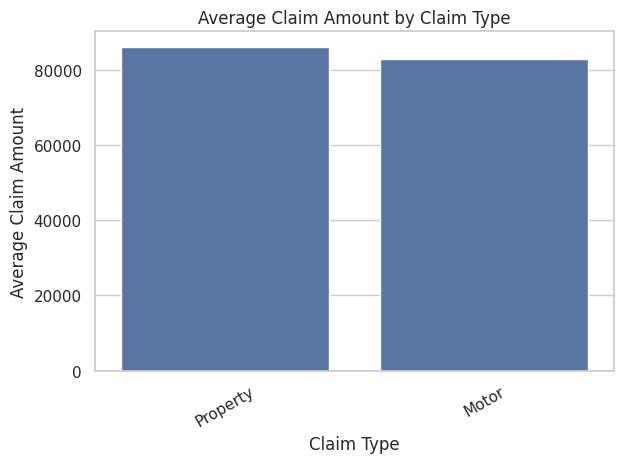

,claim_count,total_claim_amount,average_claim_amount
region,,,
South,285,53706113.72,188442.50
West,275,14255197.96,51837.08
North,230,13656843.01,59377.58
Central,205,8925183.10,43537.48
East,191,9015830.72,47203.30


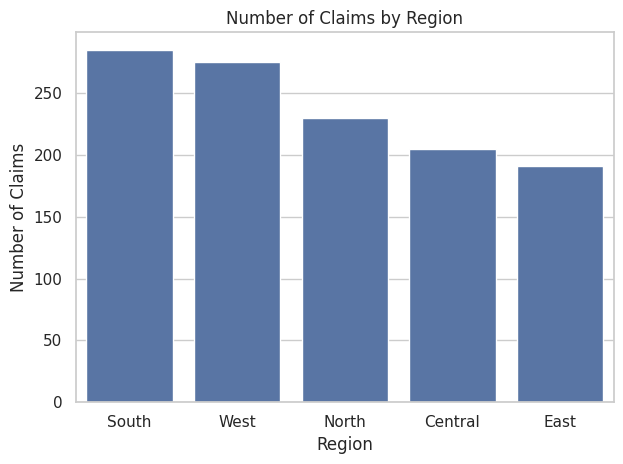

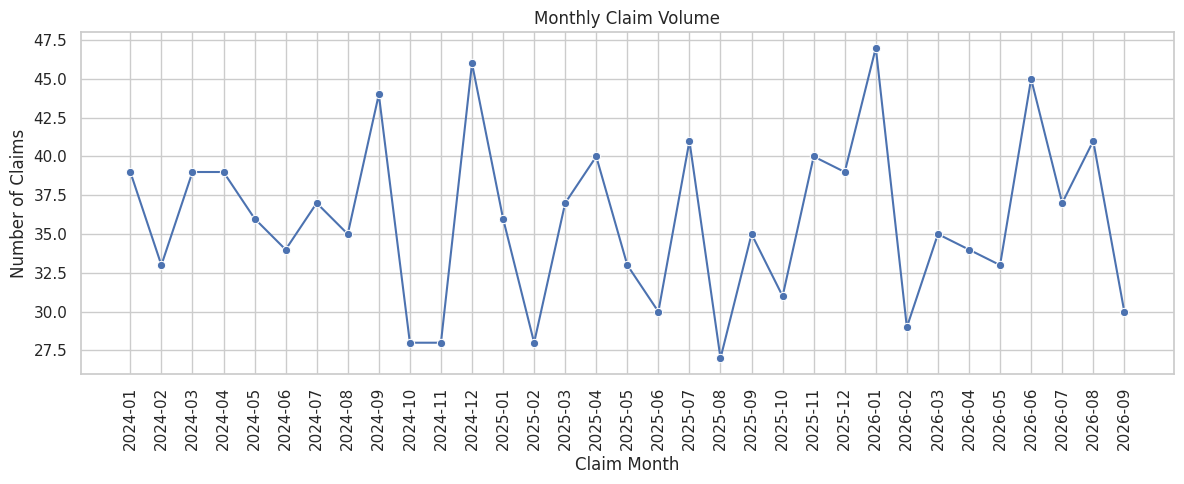

In [ ]:
print("Numerical summary:")
display(analysis.describe(include="number").T)

print("\nCategorical summary:")
display(analysis.describe(include="object").T)



claim_type_summary = (
    analysis.groupby("claim_type", dropna=False)
    .agg(
        claim_count=("claim_number", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
        median_claim_amount=("claim_amount", "median")
    )
    .sort_values("average_claim_amount", ascending=False)
)

display(claim_type_summary.round(2))


plot_data = claim_type_summary.reset_index()

sns.barplot(
    data=plot_data,
    x="claim_type",
    y="average_claim_amount"
)

plt.title("Average Claim Amount by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Average Claim Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



regional_summary = (
    analysis.groupby("region", dropna=False)
    .agg(
        claim_count=("claim_number", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean")
    )
    .sort_values("claim_count", ascending=False)
)

display(regional_summary.round(2))
sns.barplot(
    data=regional_summary.reset_index(),
    x="region",
    y="claim_count"
)

plt.title("Number of Claims by Region")
plt.xlabel("Region")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()



monthly_claims = (
    analysis.dropna(subset=["claim_date"])
    .assign(claim_month=lambda df: df["claim_date"].dt.to_period("M").astype(str))
    .groupby("claim_month")
    .agg(
        claim_count=("claim_number", "nunique"),
        total_claim_amount=("claim_amount", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_claims,
    x="claim_month",
    y="claim_count",
    marker="o"
)

plt.title("Monthly Claim Volume")
plt.xlabel("Claim Month")
plt.ylabel("Number of Claims")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

,claim_count,average_settlement_days,median_settlement_days,max_settlement_days
claim_type,,,,
Property,435,15.47,15.0,31
Motor,739,15.20,15.0,33


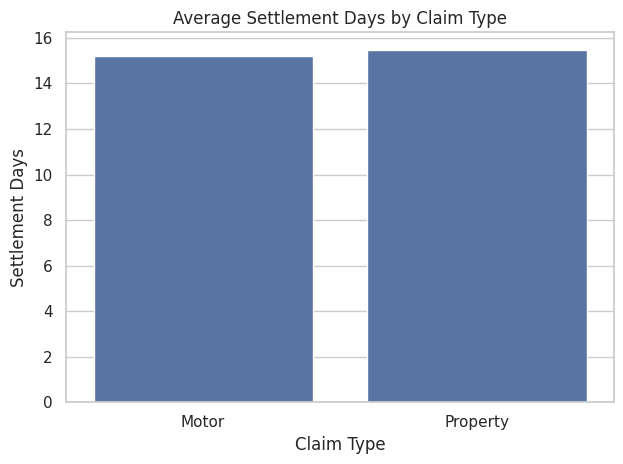

,claim_count,average_settlement_days,median_settlement_days
process_stage,,,
Investigation,268,18.07,18.0
Approval,197,17.29,17.0
Payment,118,15.14,14.0
Assessment,231,13.49,13.0
Registration,131,13.39,13.0
Document Review,229,13.36,13.0


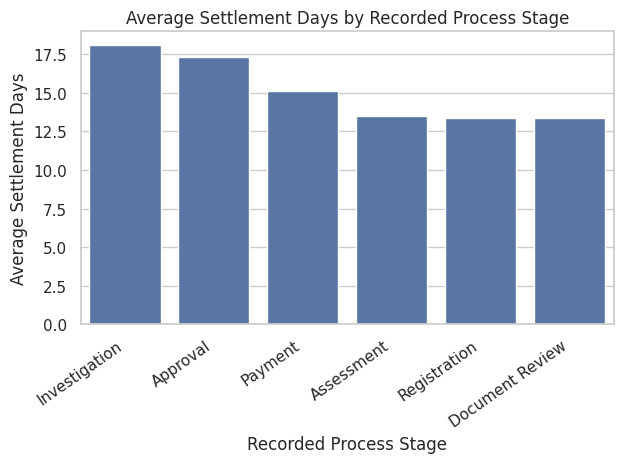

In [ ]:
valid_settlement = analysis[
    analysis["settlement_days"].between(1, 365) &
    analysis["settlement_days"].notna()
].copy()

settlement_by_type = (
    valid_settlement.groupby("claim_type", dropna=False)
    .agg(
        claim_count=("claim_number", "nunique"),
        average_settlement_days=("settlement_days", "mean"),
        median_settlement_days=("settlement_days", "median"),
        max_settlement_days=("settlement_days", "max")
    )
    .sort_values("average_settlement_days", ascending=False)
)

display(settlement_by_type.round(2))

sns.barplot(
    data=valid_settlement,
    x="claim_type",
    y="settlement_days",
    errorbar=None
)

plt.title("Average Settlement Days by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Settlement Days")
plt.tight_layout()
plt.show()

stage_summary = (
    valid_settlement.groupby("process_stage", dropna=False)
    .agg(
        claim_count=("claim_number", "nunique"),
        average_settlement_days=("settlement_days", "mean"),
        median_settlement_days=("settlement_days", "median")
    )
    .sort_values("average_settlement_days", ascending=False)
)

display(stage_summary.round(2))



stage_plot = stage_summary.reset_index()

sns.barplot(
    data=stage_plot,
    x="process_stage",
    y="average_settlement_days"
)

plt.title("Average Settlement Days by Recorded Process Stage")
plt.xlabel("Recorded Process Stage")
plt.ylabel("Average Settlement Days")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,claim_count,average_claim_amount,median_claim_amount,total_claim_amount
severity,,,,
Critical,93,465395.51,84999.78,43281782.68
High,323,77041.14,41802.38,24884288.10
Medium,482,51936.06,24823.08,25033179.26
Unknown,12,22335.64,17852.57,268027.64
Low,276,22072.07,17839.79,6091890.83


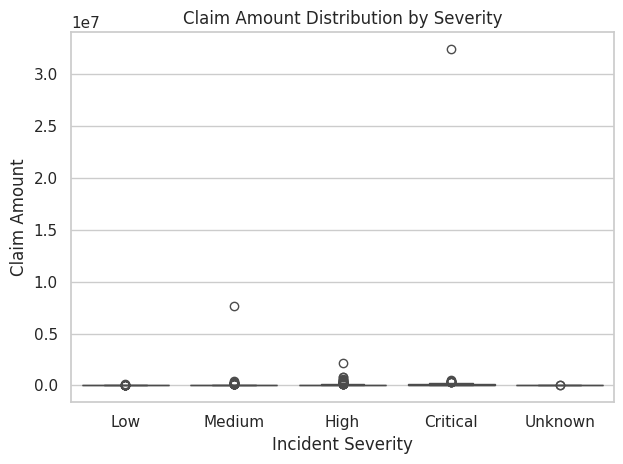

,investigation_claims,average_settlement_days,average_claim_amount
assignee,,,
S. Priya,53,18.17,54001.34
M. Divya,51,16.75,37363.88
R. Arun,51,18.82,45473.73
A. Kumar,42,17.33,59510.60
K. Sanjay,38,18.42,37336.07
P. Nila,34,18.76,38085.77


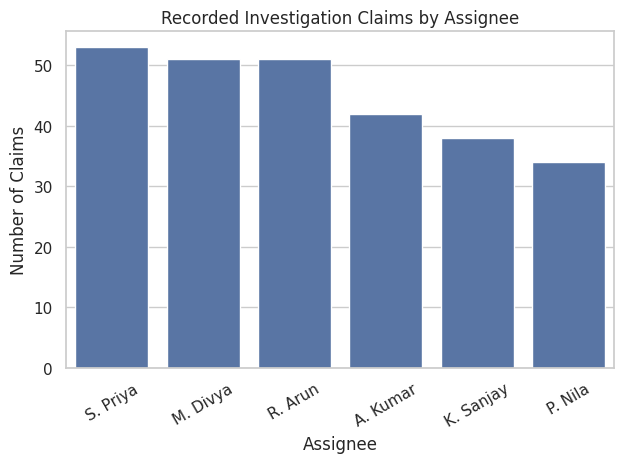

,claim_count,average_settlement_days,median_settlement_days
severity,,,
Critical,93,22.53,23.0
High,319,17.30,17.0
Medium,479,14.45,14.0
Low,273,12.14,12.0
Unknown,10,11.50,10.5


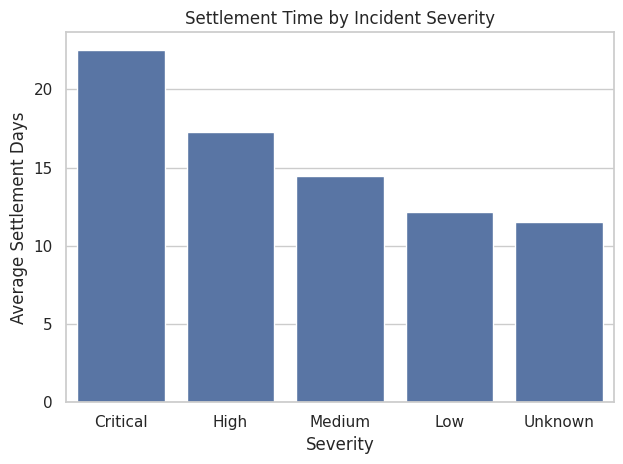

In [ ]:
severity_summary = (
    analysis.groupby("severity", dropna=False)
    .agg(
        claim_count=("claim_number", "nunique"),
        average_claim_amount=("claim_amount", "mean"),
        median_claim_amount=("claim_amount", "median"),
        total_claim_amount=("claim_amount", "sum")
    )
    .sort_values("average_claim_amount", ascending=False)
)

display(severity_summary.round(2))

severity_order = ["Low", "Medium", "High", "Critical", "Unknown"]

sns.boxplot(
    data=analysis,
    x="severity",
    y="claim_amount",
    order=severity_order
)

plt.title("Claim Amount Distribution by Severity")
plt.xlabel("Incident Severity")
plt.ylabel("Claim Amount")
plt.tight_layout()
plt.show()


investigation_data = analysis[
    analysis["process_stage"].eq("Investigation")
].copy()

investigation_summary = (
    investigation_data.groupby("assignee", dropna=False)
    .agg(
        investigation_claims=("claim_number", "nunique"),
        average_settlement_days=("settlement_days", "mean"),
        average_claim_amount=("claim_amount", "mean")
    )
    .sort_values("investigation_claims", ascending=False)
)


display(investigation_summary.round(2))

sns.barplot(
    data=investigation_summary.reset_index(),
    x="assignee",
    y="investigation_claims"
)

plt.title("Recorded Investigation Claims by Assignee")
plt.xlabel("Assignee")
plt.ylabel("Number of Claims")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



severity_settlement = (
    valid_settlement.groupby("severity", dropna=False)
    .agg(
        claim_count=("claim_number", "nunique"),
        average_settlement_days=("settlement_days", "mean"),
        median_settlement_days=("settlement_days", "median")
    )
    .sort_values("average_settlement_days", ascending=False)
)

display(severity_settlement.round(2))

sns.barplot(
    data=severity_settlement.reset_index(),
    x="severity",
    y="average_settlement_days"
)

plt.title("Settlement Time by Incident Severity")
plt.xlabel("Severity")
plt.ylabel("Average Settlement Days")
plt.tight_layout()
plt.show()

In [ ]:
analysis["claim_year"] = analysis["claim_date"].dt.year
analysis["claim_month"] = analysis["claim_date"].dt.month
analysis["claim_day_of_week"] = (
    analysis["claim_date"].dt.day_name()
)

analysis["claim_quarter"] = (
    analysis["claim_date"].dt.quarter
)

display(analysis[
    ["claim_date", "claim_year", "claim_month",
     "claim_day_of_week", "claim_quarter"]
].head())


analysis["claim_value_band"] = pd.cut(
    analysis["claim_amount"],
    bins=[-np.inf, 10000, 50000, 150000, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

display(
    analysis.groupby(
        "claim_value_band",
        observed=False
    )["claim_number"].nunique()
)


analysis["settlement_category"] = np.select(
    [
        analysis["settlement_days"].isna(),
        analysis["settlement_days"] <= 0,
        analysis["settlement_days"] > 365,
        analysis["settlement_days"] <= 7,
        analysis["settlement_days"] <= 30
    ],
    [
        "Missing",
        "Invalid",
        "Review Required",
        "Fast",
        "Normal"
    ],
    default="Delayed"
)

display(
    analysis["settlement_category"].value_counts(dropna=False)
)


analysis["missing_incident_flag"] = (
    analysis["incident_type"].isna() |
    analysis["location_type"].isna() |
    analysis["severity"].isna() |
    analysis["incident_type"].eq("Unknown") |
    analysis["location_type"].eq("Unknown") |
    analysis["severity"].eq("Unknown")
)

analysis["high_value_flag"] = (
    analysis["amount_outlier_flag"]
    if "amount_outlier_flag" in analysis.columns
    else analysis["claim_amount"] > upper_bound
)

analysis["invalid_settlement_flag"] = (
    analysis["settlement_days"].isna() |
    (analysis["settlement_days"] <= 0) |
    (analysis["settlement_days"] > 365)
)

display(analysis[
    ["claim_number", "missing_incident_flag",
     "high_value_flag", "invalid_settlement_flag"]
].head())



analysis["investigation_priority"] = np.select(
    [
        analysis["severity"].isin(["Critical", "High"]) &
        (analysis["claim_amount"] > upper_bound),

        analysis["severity"].isin(["Critical", "High"]),

        analysis["claim_amount"] > upper_bound
    ],
    [
        "High",
        "Medium",
        "Medium"
    ],
    default="Standard"
)

display(
    analysis["investigation_priority"].value_counts()
)

,claim_date,claim_year,claim_month,claim_day_of_week,claim_quarter
0,2025-01-13,2025,1,Monday,1
1,2025-09-22,2025,9,Monday,3
2,2025-07-20,2025,7,Sunday,3
3,2024-03-03,2024,3,Sunday,1
4,2025-11-17,2025,11,Monday,4


,claim_number
claim_value_band,
Low,143
Medium,719
High,262
Very High,62


,count
settlement_category,
Normal,1045
Fast,121
Invalid,9
Delayed,8
Review Required,3


,claim_number,missing_incident_flag,high_value_flag,invalid_settlement_flag
0,CLM00001,False,False,False
1,CLM00002,False,False,False
2,CLM00003,False,False,False
3,CLM00004,False,True,False
4,CLM00005,False,False,False


,count
investigation_priority,
Standard,748
Medium,355
High,83


,claim_amount,annual_premium,policy_tenure_years,customer_tenure_years,settlement_days
claim_amount,1.00,0.03,-0.03,0.01,0.00
annual_premium,0.03,1.00,0.06,-0.01,-0.02
policy_tenure_years,-0.03,0.06,1.00,-0.01,0.02
customer_tenure_years,0.01,-0.01,-0.01,1.00,0.02
settlement_days,0.00,-0.02,0.02,0.02,1.00


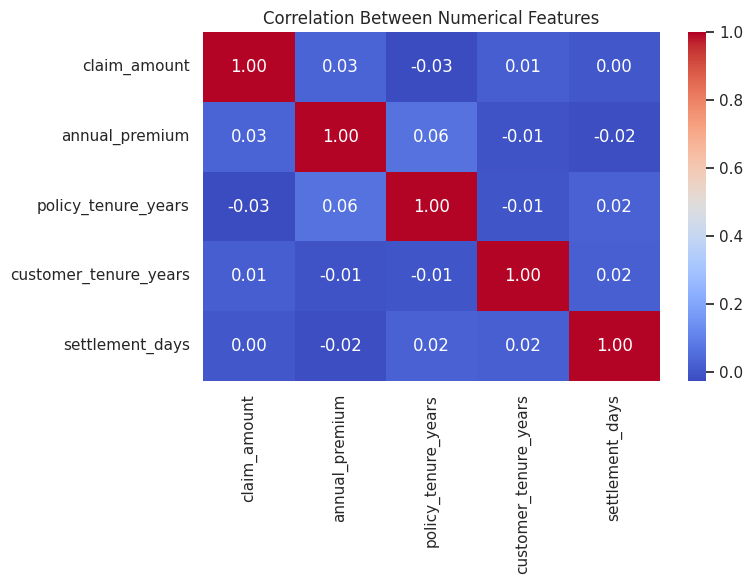

In [ ]:
numeric_cols = [
    "claim_amount",
    "annual_premium",
    "policy_tenure_years",
    "customer_tenure_years",
    "settlement_days"
]

correlation_data = analysis[numeric_cols].corr()

display(correlation_data.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
categorical_features = [
    "claim_type",
    "status",
    "region",
    "policy_type",
    "incident_type",
    "location_type",
    "severity",
    "process_stage"
]

encoded_data = pd.get_dummies(
    analysis[categorical_features].fillna("Unknown"),
    columns=categorical_features,
    dtype=int
)

print("Encoded shape:", encoded_data.shape)
display(encoded_data.head())


feature_columns = [
    "claim_amount",
    "annual_premium",
    "policy_tenure_years",
    "customer_tenure_years",
    "settlement_days",
    "claim_type",
    "status",
    "region",
    "policy_type",
    "severity",
    "process_stage",
    "investigation_priority"
]

feature_data = analysis[
    [col for col in feature_columns if col in analysis.columns]
].copy()

print("Selected features:")
print(feature_data.columns.tolist())

display(feature_data.head())

Encoded shape: (1186, 39)


,claim_type_Motor,claim_type_Property,status_Pending,status_Processing,status_Rejected,status_Settled,region_Central,region_East,region_North,region_South,region_West,policy_type_Commercial Property,policy_type_Home,policy_type_Motor,policy_type_Property,incident_type_Accidental Damage,incident_type_Collision,incident_type_Fire,incident_type_Flood,incident_type_Storm,incident_type_Theft,incident_type_Unknown,location_type_Highway,location_type_Industrial Area,location_type_Residential,location_type_Rural,location_type_Unknown,location_type_Urban,severity_Critical,severity_High,severity_Low,severity_Medium,severity_Unknown,process_stage_Approval,process_stage_Assessment,process_stage_Document Review,process_stage_Investigation,process_stage_Payment,process_stage_Registration
0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0
1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0
2,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0
3,0,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
4,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1


Selected features:
['claim_amount', 'annual_premium', 'policy_tenure_years', 'customer_tenure_years', 'settlement_days', 'claim_type', 'status', 'region', 'policy_type', 'severity', 'process_stage', 'investigation_priority']


,claim_amount,annual_premium,policy_tenure_years,customer_tenure_years,settlement_days,claim_type,status,region,policy_type,severity,process_stage,investigation_priority
0,50087.51,37531.17,5,3,27,Motor,Settled,West,Home,Critical,Investigation,Medium
1,48732.18,14567.59,7,8,19,Motor,Settled,Central,Property,High,Assessment,Medium
2,63531.21,41027.87,9,2,17,Property,Rejected,Central,Commercial Property,Medium,Investigation,Standard
3,162547.30,21439.91,3,10,12,Property,Settled,South,Property,Medium,Payment,Medium
4,83951.50,15813.60,8,4,7,Motor,Settled,South,Motor,High,Registration,Medium


In [ ]:
analysis_clean = analysis.copy()
analysis_clean["valid_claim_amount"] = (
    analysis_clean["claim_amount"].where(
        analysis_clean["claim_amount"] > 0
    )
)
analysis_clean["valid_settlement_days"] = (
    analysis_clean["settlement_days"].where(
        analysis_clean["settlement_days"].between(1, 365)
    )
)

print("Analytical dataset shape:", analysis_clean.shape)
display(analysis_clean.head())


output_dir = Path("/content/shieldsure_output")
output_dir.mkdir(exist_ok=True)

analysis_clean.to_csv(
    output_dir / "cleaned_claims_analysis.csv",
    index=False
)

claim_type_summary.to_csv(
    output_dir / "claim_type_summary.csv"
)

regional_summary.to_csv(
    output_dir / "regional_summary.csv"
)

settlement_by_type.to_csv(
    output_dir / "settlement_summary.csv"
)

stage_summary.to_csv(
    output_dir / "process_stage_summary.csv"
)

severity_summary.to_csv(
    output_dir / "severity_summary.csv"
)

investigation_summary.to_csv(
    output_dir / "investigation_summary.csv"
)

print("All CSV files exported successfully!")


excel_path = output_dir / "ShieldSure_EDA_Results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    analysis_clean.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )
    claim_type_summary.to_excel(
        writer, sheet_name="Claim_Type", index=True
    )
    regional_summary.to_excel(
        writer, sheet_name="Regional", index=True
    )
    settlement_by_type.to_excel(
        writer, sheet_name="Settlement", index=True
    )
    stage_summary.to_excel(
        writer, sheet_name="Process_Stage", index=True
    )
    severity_summary.to_excel(
        writer, sheet_name="Severity", index=True
    )
    investigation_summary.to_excel(
        writer, sheet_name="Investigation", index=True
    )

print("Excel workbook created:", excel_path)

Analytical dataset shape: (1186, 32)


,claim_number,customer_id,policy_id,claim_date,claim_type,claim_amount,status,invalid_amount_flag,amount_outlier_flag,policy_type,annual_premium,policy_tenure_years,region,customer_tenure_years,incident_type,location_type,severity,assignee,process_stage,settlement_days,invalid_settlement_flag,claim_year,claim_month,claim_day_of_week,claim_quarter,claim_value_band,settlement_category,missing_incident_flag,high_value_flag,investigation_priority,valid_claim_amount,valid_settlement_days
0,CLM00001,CUS00163,POL00074,2025-01-13,Motor,50087.51,Settled,False,False,Home,37531.17,5,West,3,Accidental Damage,Urban,Critical,R. Arun,Investigation,27,False,2025,1,Monday,1,High,Normal,False,False,Medium,50087.51,27.0
1,CLM00002,CUS00391,POL00288,2025-09-22,Motor,48732.18,Settled,False,False,Property,14567.59,7,Central,8,Flood,Rural,High,A. Kumar,Assessment,19,False,2025,9,Monday,3,Medium,Normal,False,False,Medium,48732.18,19.0
2,CLM00003,CUS00356,POL00319,2025-07-20,Property,63531.21,Rejected,False,False,Commercial Property,41027.87,9,Central,2,Storm,Rural,Medium,R. Arun,Investigation,17,False,2025,7,Sunday,3,High,Normal,False,False,Standard,63531.21,17.0
3,CLM00004,CUS00509,POL00248,2024-03-03,Property,162547.30,Settled,False,True,Property,21439.91,3,South,10,Theft,Industrial Area,Medium,M. Divya,Payment,12,False,2024,3,Sunday,1,Very High,Normal,False,True,Medium,162547.30,12.0
4,CLM00005,CUS00325,POL00782,2025-11-17,Motor,83951.50,Settled,False,False,Motor,15813.60,8,South,4,Theft,Rural,High,K. Sanjay,Registration,7,False,2025,11,Monday,4,High,Fast,False,False,Medium,83951.50,7.0


All CSV files exported successfully!
Excel workbook created: /content/shieldsure_output/ShieldSure_EDA_Results.xlsx


In [ ]:
from google.colab import files

files.download(
    "/content/shieldsure_output/cleaned_claims_analysis.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "/content/shieldsure_output/ShieldSure_EDA_Results.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

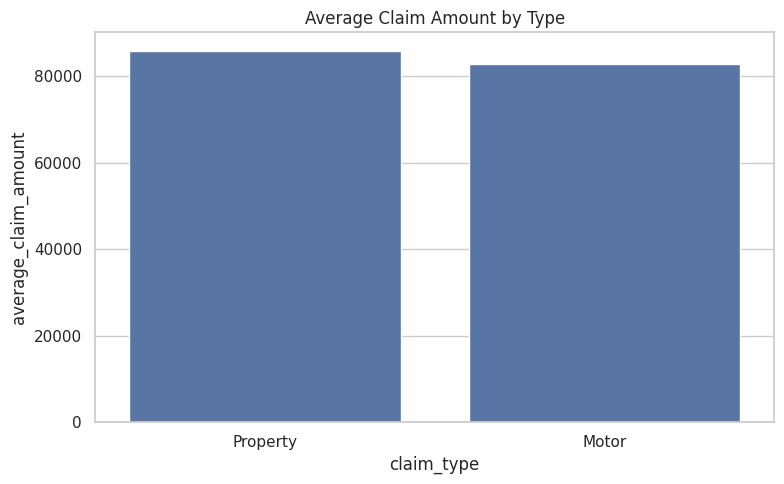

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=claim_type_summary.reset_index(),
    x="claim_type",
    y="average_claim_amount"
)

plt.title("Average Claim Amount by Type")
plt.tight_layout()

plt.savefig(
    "/content/shieldsure_output/claim_value_by_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
highest_avg_type = claim_type_summary[
    "average_claim_amount"
].idxmax()

highest_volume_region = regional_summary[
    "claim_count"
].idxmax()

longest_settlement_type = settlement_by_type[
    "average_settlement_days"
].idxmax()

longest_stage = stage_summary[
    "average_settlement_days"
].idxmax()

highest_severity = severity_summary[
    "average_claim_amount"
].idxmax()

print("SHIELDSURE BUSINESS FINDINGS")
print("-" * 40)

print("Highest average claim type:", highest_avg_type)
print("Highest claim-volume region:", highest_volume_region)
print("Longest average settlement by claim type:", longest_settlement_type)
print("Stage with highest associated settlement time:", longest_stage)
print("Severity with highest average claim amount:", highest_severity)

SHIELDSURE BUSINESS FINDINGS
----------------------------------------
Highest average claim type: Property
Highest claim-volume region: South
Longest average settlement by claim type: Property
Stage with highest associated settlement time: Investigation
Severity with highest average claim amount: Critical


In [ ]:
quality_report = pd.DataFrame({
    "Metric": [
        "Original claim rows",
        "Unique claims retained",
        "Duplicate claim rows removed",
        "Missing incident details",
        "Invalid claim amounts",
        "Potential claim amount outliers",
        "Invalid settlement durations"
    ],
    "Value": [
        len(claims),
        len(claims_clean),
        len(claims) - len(claims_clean),
        int(analysis["missing_incident_flag"].sum()),
        int((analysis["claim_amount"] <= 0).sum()),
        int(analysis["amount_outlier_flag"].sum()),
        int(analysis["invalid_settlement_flag"].sum())
    ]
})

display(quality_report)

,Metric,Value
0,Original claim rows,1200
1,Unique claims retained,1186
2,Duplicate claim rows removed,14
3,Missing incident details,45
4,Invalid claim amounts,1
5,Potential claim amount outliers,105
6,Invalid settlement durations,12
